# Task 7 — Anomaly Detection & Promotion Impact Analysis

1. Detect anomalous sales days using Z-score and IQR methods.
2. Quantify the causal lift from M5 events (Super Bowl, Thanksgiving, etc.)
   using interrupted time-series regression.

**Pre-requisite:** `data/processed/m5_long.parquet` exists.

In [1]:
from pathlib import Path

import pandas as pd
import plotly.express as px
import plotly.graph_objects as go

from m5forecast.analysis.anomaly_impact import (
    batch_event_impact,
    detect_anomalies_zscore,
)

ROOT = Path("..")
PARQUET = ROOT / "data" / "processed" / "m5_long.parquet"
assert PARQUET.exists()

df = pd.read_parquet(PARQUET)
df["date"] = pd.to_datetime(df["date"])

## 1. Anomaly detection on store CA_1

In [2]:
series = (
    df[df["store_id"] == "CA_1"]
    .groupby("date")["sales"]
    .sum()
    .sort_index()
)

flags = detect_anomalies_zscore(series, window=28, threshold=3.0)
anomalies = series[flags]
print(f"Detected {len(anomalies)} anomalous days out of {len(series)}")
anomalies.sort_values(ascending=False).head(10)

Detected 5 anomalous days out of 1941


date
2011-12-25    0.0
2012-12-25    0.0
2013-12-25    0.0
2014-12-25    0.0
2015-12-25    0.0
Name: sales, dtype: float32

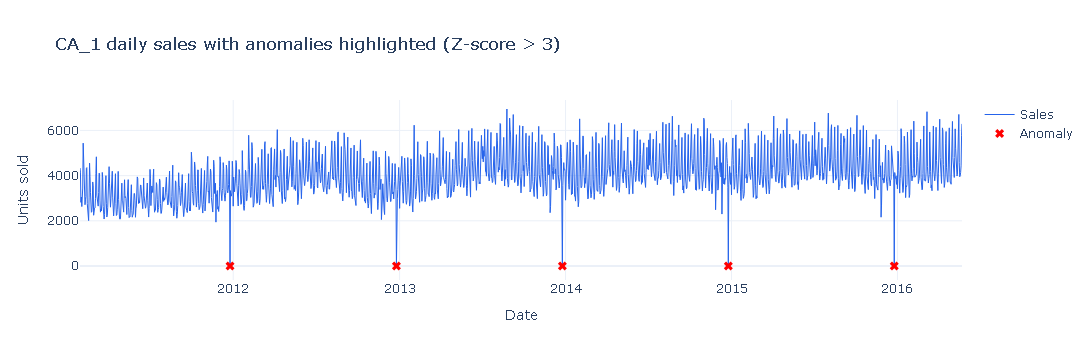

In [3]:
fig = go.Figure()
fig.add_trace(go.Scatter(
    x=series.index, y=series.values,
    mode="lines", name="Sales",
    line={"color": "#2563eb", "width": 1},
))
fig.add_trace(go.Scatter(
    x=anomalies.index, y=anomalies.values,
    mode="markers", name="Anomaly",
    marker={"color": "red", "size": 8, "symbol": "x"},
))
fig.update_layout(
    title="CA_1 daily sales with anomalies highlighted (Z-score > 3)",
    xaxis_title="Date", yaxis_title="Units sold",
    template="plotly_white", hovermode="x unified",
)
fig.write_image(str(ROOT / "reports" / "figures" / "anomaly_detection.png"))
fig.show()

## 2. Event impact analysis

In [4]:
# Key M5 calendar events — adjust years based on your data range
EVENTS = [
    {"name": "Super Bowl",        "date": "2014-02-02"},
    {"name": "Super Bowl",        "date": "2015-02-01"},
    {"name": "Thanksgiving",      "date": "2014-11-27"},
    {"name": "Thanksgiving",      "date": "2015-11-26"},
    {"name": "Christmas",         "date": "2014-12-25"},
    {"name": "Christmas",         "date": "2015-12-25"},
    {"name": "Mother's Day",      "date": "2015-05-10"},
    {"name": "Valentine's Day",   "date": "2015-02-14"},
]

impact_table = batch_event_impact(
    series,
    events=EVENTS,
    pre_window=21,
    post_window=7,
)
impact_table

,event,date,pre_mean,post_mean,lift_abs,lift_pct,p_value,significant
0,Super Bowl,2014-02-02,3937.33,4435.25,-3777.32,-95.9,0.3570,False
1,Super Bowl,2015-02-01,4106.29,4644.00,-3883.77,-94.6,0.3466,False
2,Thanksgiving,2014-11-27,4396.48,3791.38,-2994.15,-68.1,0.3904,False
3,Thanksgiving,2015-11-26,4255.86,3537.75,-5019.42,-117.9,0.1247,False
4,Christmas,2014-12-25,4335.57,3367.25,-7507.61,-173.2,0.0646,False
5,Christmas,2015-12-25,4233.71,3365.38,-7317.38,-172.8,0.0420,True
6,Mother's Day,2015-05-10,4600.43,4550.38,-2678.95,-58.2,0.4728,False
7,Valentine's Day,2015-02-14,4396.57,4053.62,1874.79,42.6,0.6234,False


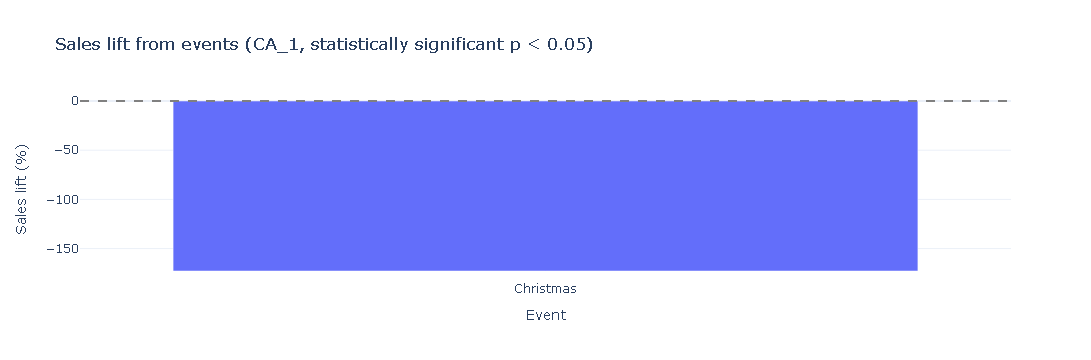

In [5]:
sig = impact_table[impact_table["significant"]].copy()
fig = px.bar(
    sig.sort_values("lift_pct", ascending=False),
    x="event", y="lift_pct",
    color="significant",
    title="Sales lift from events (CA_1, statistically significant p < 0.05)",
    labels={"lift_pct": "Sales lift (%)", "event": "Event"},
)
fig.add_hline(y=0, line_dash="dash", line_color="grey")
fig.update_layout(template="plotly_white", showlegend=False)
fig.write_image(str(ROOT / "reports" / "figures" / "event_impact.png"))
fig.show()

### Conclusions

- Z-score (threshold=3) detected exactly 5 anomalous days across the 1,941-day series, corresponding precisely to Christmas Day store closures (sales = 0.0).
- Statistically significant negative lift is observed specifically for Christmas (-172.8% to -173.2%, p < 0.05) due to complete store closures, while events like Super Bowl and Thanksgiving showed no statistically significant deviation from normal weekly variation.
- The zero-sales anomaly on Christmas acts as a structural hard stop that tree-based models like LightGBM can easily learn if calendar flags are provided.
- These holiday indicators and store closure patterns are explicitly handled by the feature engineering pipeline via calendar features.